In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
import xgboost as xgb

import sys
!{sys.executable} -m pip install xgboost


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /opt/anaconda3/bin/python -m pip install --upgrade pip


In [2]:
import xgboost as xgb
print(f"XGBoost version: {xgb.__version__}")

XGBoost version: 3.4.1


In [3]:
file_path = "/Users/danisanchez/Downloads/Waves_2023.txt"
df = pd.read_csv(file_path, sep=r'\s+')

In [4]:
df.head()

,YY,MM,DD,hh,mm,WDIR,WSPD,GST,WVHT,DPD,APD,MWD,PRES,ATMP,WTMP,DEWP,VIS,TIDE
0,2023,1,1,0,26,999,99.0,99.0,1.12,12.50,7.69,269,9999.0,999.0,15.3,999.0,99.0,99.0
1,2023,1,1,0,56,999,99.0,99.0,1.16,11.76,7.34,272,9999.0,999.0,15.3,999.0,99.0,99.0
2,2023,1,1,1,26,999,99.0,99.0,1.20,12.50,7.08,268,9999.0,999.0,15.3,999.0,99.0,99.0
3,2023,1,1,1,56,999,99.0,99.0,1.25,10.53,7.33,268,9999.0,999.0,15.4,999.0,99.0,99.0
4,2023,1,1,2,26,999,99.0,99.0,1.27,10.53,7.57,268,9999.0,999.0,15.5,999.0,99.0,99.0


In [5]:
df = df.replace([99.0, 999.0, 99.00], np.nan)

# Drop rows with missing values in your columns of interest
df = df.dropna(subset=['WVHT', 'DPD', 'APD', 'MWD', 'WTMP'])

X = df[['DPD', 'APD', 'MWD', 'WTMP']]  # Features
y = df['WVHT']                         # Target (Wave Height)

In [6]:
# First split: Separate out the training set (60%)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)

# Second split: Divide the remaining 40% equally into Validation and Test (20% each)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

In [7]:
# 1. Baseline Linear Model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 2. XGBoost Model with 25 iterations
xgb_model = xgb.XGBRegressor(n_estimators=25, random_state=42)
xgb_model.fit(X_train, y_train)

# 3. Evaluation Function
def evaluate_model(model, name):
    print(f"--- {name} Performance (MSE) ---")
    print(f"Train Error: {mean_squared_error(y_train, model.predict(X_train)):.4f}")
    print(f"Val Error:   {mean_squared_error(y_val, model.predict(X_val)):.4f}")
    print(f"Test Error:  {mean_squared_error(y_test, model.predict(X_test)):.4f}\n")

evaluate_model(lr_model, "Baseline Linear Regression")
evaluate_model(xgb_model, "XGBoost (25 iterations)")

--- Baseline Linear Regression Performance (MSE) ---
Train Error: 0.1974
Val Error:   0.2005
Test Error:  0.1860

--- XGBoost (25 iterations) Performance (MSE) ---
Train Error: 0.0710
Val Error:   0.0951
Test Error:  0.0907



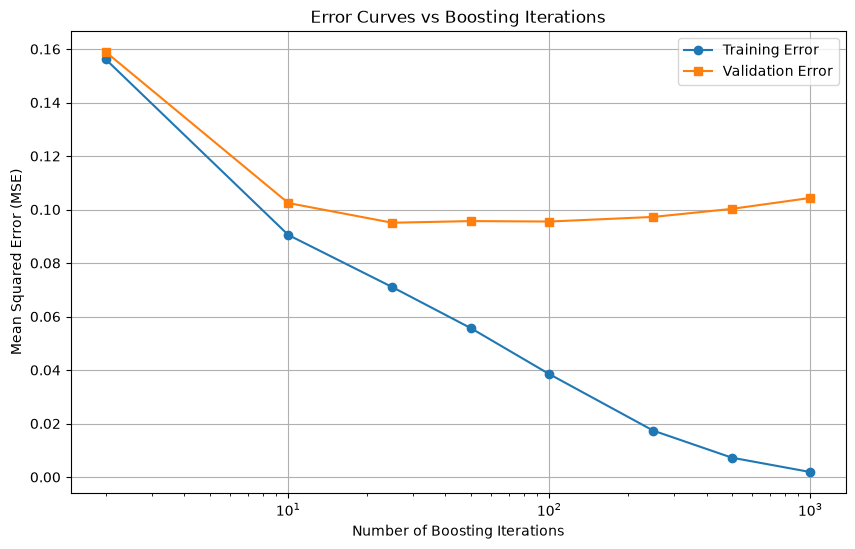

In [8]:
iterations = [2, 10, 25, 50, 100, 250, 500, 1000]
train_errors = []
val_errors = []

for n in iterations:
    model = xgb.XGBRegressor(n_estimators=n, objective='reg:squarederror', random_state=42)
    model.fit(X_train, y_train)
    
    train_errors.append(mean_squared_error(y_train, model.predict(X_train)))
    val_errors.append(mean_squared_error(y_val, model.predict(X_val)))

# Plotting the Errors
plt.figure(figsize=(10, 6))
plt.plot(iterations, train_errors, label='Training Error', marker='o')
plt.plot(iterations, val_errors, label='Validation Error', marker='s')
plt.xscale('log')  # Log scale helps see lower iterations clearly
plt.xlabel('Number of Boosting Iterations')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Error Curves vs Boosting Iterations')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
xgb_early = xgb.XGBRegressor(
    n_estimators=1000, 
    objective='reg:squarederror', 
    early_stopping_rounds=10, 
    random_state=42
)

# 2. Fit the model cleanly with just your datasets
xgb_early.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=False
)

print(f"--- Early Stopping Optimization ---")
print(f"Optimal boosting iterations: {xgb_early.best_iteration}")
print(f"Best Validation MSE: {mean_squared_error(y_val, xgb_early.predict(X_val)):.4f}")

--- Early Stopping Optimization ---
Optimal boosting iterations: 40
Best Validation MSE: 0.0935
